# Paulson et al. 2020 — Merkel Cell Carcinoma (skin, 10x)
## 04 · EMT-transcription-factor expression (unconditional final step)

The EMT-TF readout runs regardless of gate outcomes; numbered **04** here because the analysis is
non-branching (Gate 3 NA), so the branching-only correlation/modules notebooks are not produced (§6).
A wide EMT-TF panel (Snail/Zeb/Twist + FOXC/PRRX mesenchymal families; VIM excluded — a mesenchymal
marker, not a transcription factor) is scored, gated on detectable expression, and each factor
classified by the pseudotime end it loads onto. The two most informative factors (origin/body vs
terminus) are overlaid as thresholded expressers on a grey manifold (reference categorical style).

In [ ]:
import os, sys, glob, warnings
warnings.filterwarnings('ignore')
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
import numpy as np, pandas as pd
import scanpy as sc
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [ ]:
name = os.path.basename(os.getcwd())
cat  = os.path.basename(os.path.dirname(os.getcwd()))
pth  = os.path.join(*([os.pardir]*4))
pth_data = os.path.join(pth, 'data')
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'mesencontext', 'claude', cat, name)
os.makedirs(pth_fig, exist_ok=True)

In [ ]:
# load signatures (has pseudotime + house layout)
adata = sc.read_h5ad(os.path.join(pth_out, 'signatures.h5ad'))
adata.obsm['X_umap'] = adata.obsm['X_umap_lin']
t = adata.obs['t'].values; tn = (t-t.min())/(t.max()-t.min())
print('cells:', adata.shape[0], '| pseudotime', round(t.min(),2), '->', round(t.max(),2))

cells: 12124 | pseudotime 0.0 -> 9.41


In [ ]:
# score a WIDE EMT-TF panel; gate on detectable expression; classify each by pseudotime end.
panel = ['SNAI1','SNAI2','ZEB1','ZEB2','TWIST1','TWIST2','FOXC1','FOXC2','PRRX1','PRRX2']
present = [g for g in panel if g in adata.var_names]
print('panel genes present in var:', present)
early = tn <= np.quantile(tn, 1/3); late = tn >= np.quantile(tn, 2/3)
X = adata[:,present].X; X = X.toarray() if hasattr(X,'toarray') else np.asarray(X)
rows=[]
for j,g in enumerate(present):
    x = X[:,j]; expr = x>0; rho,_ = spearmanr(tn, x)
    rows.append((g, round(expr.mean(),3), round(x[early].mean(),3), round(x[late].mean(),3), round(rho,3)))
df = pd.DataFrame(rows, columns=['TF','frac_expr','mean_early','mean_late','rho_vs_t']).sort_values('rho_vs_t')
df['end'] = np.where(df.mean_early > df.mean_late, 'EARLY(origin)', 'LATE(terminus)')
print(df.to_string(index=False))
ok = df[df.frac_expr > 0.03]
body_tf = ok.sort_values('rho_vs_t').iloc[0]['TF']
terminus_tf = ok.sort_values('rho_vs_t').iloc[-1]['TF']
n_early = int((ok.end=='EARLY(origin)').sum())
print(f'\nexpressed EMT-TFs (frac>3%): {len(ok)}; classified EARLY(origin): {n_early}')
print(f'origin/body factor (min rho) = {body_tf}; terminus factor (max rho) = {terminus_tf}')

panel genes present in var: ['SNAI1', 'ZEB1', 'ZEB2']
   TF  frac_expr  mean_early  mean_late  rho_vs_t           end
 ZEB1      0.144       0.032      0.029    -0.054 EARLY(origin)
 ZEB2      0.191       0.049      0.042    -0.049 EARLY(origin)
SNAI1      0.012       0.003      0.002    -0.041 EARLY(origin)

expressed EMT-TFs (frac>3%): 2; classified EARLY(origin): 2
origin/body factor (min rho) = ZEB1; terminus factor (max rho) = ZEB2


overlay thresholds (upper quartile among expressers): {'ZEB1': 0.32, 'ZEB2': 0.33} | cells shown: {'ZEB1': 435, 'ZEB2': 578}
ZEB1: 14.4% expressing; 435 shown; mean pseudotime of shown = 0.57
ZEB2: 19.1% expressing; 578 shown; mean pseudotime of shown = 0.56
saved expression.pdf


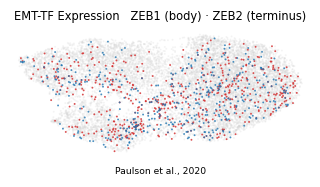

In [ ]:
# categorical overlay: thresholded expressers of the two chosen TFs on a grey manifold (reference style)
xl = adata.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
def vec(g):
    x = adata[:,g].X; return x.toarray().ravel() if hasattr(x,'toarray') else np.asarray(x).ravel()
thr={}
for g in [body_tf, terminus_tf]:
    v = vec(g); pos = v[v>0]; thr[g] = float(np.quantile(pos,0.75)) if pos.size else 0.0
sel = {g: vec(g) > thr[g] for g in [body_tf, terminus_tf]}
print('overlay thresholds (upper quartile among expressers):', {g:round(thr[g],2) for g in thr},
      '| cells shown:', {g:int(sel[g].sum()) for g in sel})
order = sorted([body_tf, terminus_tf], key=lambda g: -int(sel[g].sum()))
colors = {body_tf:'tab:blue', terminus_tf:'tab:red'}
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(adata, size=6, alpha=.25, frameon=False, show=False, ax=ax, na_color='lightgray')
for g in order:
    ap = adata[sel[g]].copy()
    sc.pl.umap(ap, na_color=colors[g], size=6, alpha=.8, frameon=False, show=False, ax=ax)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title(f'EMT-TF Expression   {body_tf} (body) · {terminus_tf} (terminus)', size=7.5)
ax.text(.5,-.14,'Paulson et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'expression.pdf'), bbox_inches='tight')
plt.show()
for g in [body_tf, terminus_tf]:
    mk = sel[g]
    print(f'{g}: {(vec(g)>0).mean()*100:.1f}% expressing; {int(mk.sum())} shown; mean pseudotime of shown = {tn[mk].mean():.2f}')
print('saved expression.pdf')